# 05, évaluation

Phase 5 de CRISP-DM, résumée dans `docs/evaluation.md`. Ce notebook évalue les recommandations que retourne `recommander()` pour Korhogo et Bouaké et pour les trois priorités, la rotation actuelle étant coton puis maïs. Il n'existe pas de vérité terrain sur la meilleure rotation, si bien que l'évaluation ne mesure pas une précision. Il appelle `moteur/evaluation.py` sans calcul propre.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from bot.langage.gabarits import resume
from bot.langage.garde_fou import ecarts
from moteur import recommander
from moteur.criteres import POIDS_PAR_PRIORITE, parts_par_culture
from moteur.evaluation import (bon_sens_cultures, bon_sens_strategies, classements, scores_publies, variantes_coton,
                               verifier_contrat)
from moteur.lieux import LIEUX_ETUDE as LIEUX
from moteur.recommander import donnees_du_lieu

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
noms = {identifiant: lieu["nom"] for identifiant, lieu in LIEUX.items()}
recos = {(i, p): recommander(i, "coton_mais", poids) for i in LIEUX for p, poids in POIDS_PAR_PRIORITE.items()}

## 1. Conformité de chaque recommandation

In [2]:
pd.DataFrame({(noms[i], p): {**verifier_contrat(r), "message_du_bot_fidele": not ecarts(resume(r), r)}
              for (i, p), r in recos.items()})

Korhogo              Bouaké             
                                    eau revenu   sol    eau revenu   sol
donnees_reelles                    True   True  True   True   True  True
au_moins_trois_strategies          True   True  True   True   True  True
une_seule_rotation_actuelle        True   True  True   True   True  True
mesure_et_calcule_sources          True   True  True   True   True  True
indicateurs_avec_plage             True   True  True   True   True  True
chaque_strategie_a_ses_elements    True   True  True   True   True  True
instabilite_nommee                 True   True  True   True   True  True
message_du_bot_fidele              True   True  True   True   True  True

**Constat.** Les six recommandations passent les huit contrôles, données réelles, au moins trois stratégies dont une seule rotation actuelle, sources de chaque élément mesuré ou calculé, plage de chaque indicateur, raisons et preuves de chaque stratégie, scénario nommé quand le classement est instable, et message du bot fidèle au garde-fou.

**Analyse.** Le critère 1 du cadrage est atteint. La fidélité du message couvre les nombres, les cultures, les traitements, les produits et les maladies, mais une phrase fausse sans aucun de ces mots peut encore passer, comme celle de l'ancien gabarit sur une saison plus sèche.

**Décision.** Le gabarit est corrigé. Il dit que le classement est incertain et laisse l'avertissement du moteur nommer le scénario. Le garde-fou refuse aussi désormais les traitements, les produits et les maladies absentes du moteur.

## 2. Vérifications de bon sens

In [3]:
for identifiant in LIEUX:
    _, contextes = donnees_du_lieu(identifiant)
    cycles = contextes["reference"].cycles
    besoins = cycles.groupby("culture")["etc_cycle_mm"].median()
    print(noms[identifiant])
    display(pd.DataFrame(bon_sens_strategies(recos[(identifiant, "eau")])
                         + bon_sens_cultures(parts_par_culture(contextes["reference"]), besoins)))

Korhogo


,verification,resultat,valeurs,portee
0,une rotation avec légumineuse a un meilleur score d'apport d'azote qu'une rotation sans,True,"avec [1.67, 2.5], sans [0.0]","vrai par construction du critère, ce n'est pas une vérification indépendante"
1,sorgho puis niébé a un score d'eau au moins égal à coton puis maïs,True,4.65 contre 4.05,compare deux rotations qui diffèrent par le coton autant que par le maïs
2,le sorgho demande moins d'eau que le maïs sur son cycle,True,453 mm contre 482 mm,"besoin FAO-56 en conditions standard, pas une tolérance à la sécheresse"
3,la pluie couvre le besoin du sorgho au moins aussi souvent que celui du maïs,True,1.00 contre 0.96,dépend aussi de la durée du cycle et de la date de semis
4,le mil demande moins d'eau que le maïs sur son cycle,True,378 mm contre 482 mm,"besoin FAO-56 en conditions standard, pas une tolérance à la sécheresse"
5,la pluie couvre le besoin du mil au moins aussi souvent que celui du maïs,False,0.92 contre 0.96,dépend aussi de la durée du cycle et de la date de semis
6,FAO-56 attribue au maïs une plus forte sensibilité du rendement au manque d'eau qu'au sorgho,True,"Ky 1.25 contre 0.9, tableau 24","connaissance sourcée, le facteur Ky n'entre pas dans les scores"


Bouaké


,verification,resultat,valeurs,portee
0,une rotation avec légumineuse a un meilleur score d'apport d'azote qu'une rotation sans,True,"avec [1.67, 2.5], sans [0.0]","vrai par construction du critère, ce n'est pas une vérification indépendante"
1,sorgho puis niébé a un score d'eau au moins égal à coton puis maïs,True,4.35 contre 2.97,compare deux rotations qui diffèrent par le coton autant que par le maïs
2,le sorgho demande moins d'eau que le maïs sur son cycle,True,390 mm contre 415 mm,"besoin FAO-56 en conditions standard, pas une tolérance à la sécheresse"
3,la pluie couvre le besoin du sorgho au moins aussi souvent que celui du maïs,True,0.96 contre 0.88,dépend aussi de la durée du cycle et de la date de semis
4,le mil demande moins d'eau que le maïs sur son cycle,True,323 mm contre 415 mm,"besoin FAO-56 en conditions standard, pas une tolérance à la sécheresse"
5,la pluie couvre le besoin du mil au moins aussi souvent que celui du maïs,True,0.92 contre 0.88,dépend aussi de la durée du cycle et de la date de semis
6,FAO-56 attribue au maïs une plus forte sensibilité du rendement au manque d'eau qu'au sorgho,True,"Ky 1.25 contre 0.9, tableau 24","connaissance sourcée, le facteur Ky n'entre pas dans les scores"


**Constat.** Toutes les vérifications passent, sauf une. À Korhogo, la pluie couvre le besoin du mil 0,92 des années contre 0,96 pour le maïs. Le sorgho demande moins d'eau que le maïs, 453 contre 482 mm à Korhogo et 390 contre 415 mm à Bouaké, et le mil encore moins. La vérification des légumineuses est vraie par construction du critère d'azote.

**Analyse.** L'échec du mil vient de son cycle de 105 jours, semé au début des pluies, qui couvre surtout le début de saison, moins arrosé. Il montre que le critère eau mesure la couverture du besoin par la pluie, et non la tolérance d'une culture au manque d'eau, que FAO-56 exprime par le facteur Ky, 1,25 pour le maïs contre 0,9 pour le sorgho.

**Décision.** La tolérance à la sécheresse est écrite parmi les limites, comme une connaissance sourcée qui n'entre pas dans les scores.

## 3. Korhogo et Bouaké

Korhogo              Bouaké             
                     eau revenu   sol    eau revenu   sol
coton_mais          4.05   2.50  0.00   2.97   2.50  0.00
coton_niebe_mais    4.27   1.67  1.67   3.40   1.67  1.67
sorgho_niebe        4.65   0.00  2.50   4.35   0.00  2.50

,Korhogo,Bouaké
0,sorgho_niebe,sorgho_niebe
1,coton_niebe_mais,coton_niebe_mais
2,coton_mais,coton_mais


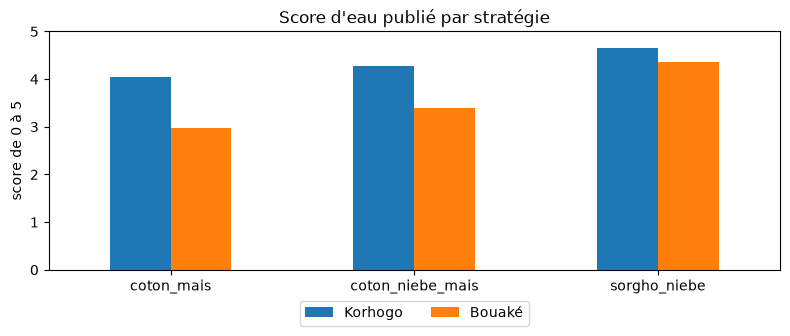

In [4]:
scores = scores_publies({noms[i]: recos[(i, "eau")] for i in LIEUX})
display(scores)
display(pd.DataFrame({noms[i]: recos[(i, p)].classement for i in LIEUX for p in ["eau"]}))

figure, axe = plt.subplots(figsize=(8, 3.5))
scores.xs("eau", axis=1, level=1).plot.bar(ax=axe, rot=0)
axe.set(title="Score d'eau publié par stratégie", ylabel="score de 0 à 5", ylim=(0, 5))
axe.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

**Constat.** Les deux villes reçoivent le même classement pour l'eau, sorgho puis niébé, puis coton, niébé puis maïs, puis coton puis maïs. Chaque stratégie a pourtant un score d'eau plus bas à Bouaké, 2,97 contre 4,05 pour coton puis maïs, 3,4 contre 4,27 pour coton, niébé puis maïs et 4,35 contre 4,65 pour sorgho puis niébé.

**Analyse.** L'écart entre les villes suit les données en valeur, Bouaké étant plus exposée au manque d'eau, mais non en classement. Le critère 3 du cadrage est respecté au sens de son énoncé validé, l'absence d'écart de classement étant expliquée.

**Décision.** L'outil montre aux deux villes la même stratégie en tête pour l'eau, avec un risque d'eau nettement plus élevé à Bouaké.

## 4. Sensibilité du classement publié

Chaque classement est reconstruit par la fonction qui construit la recommandation, avec la date de semis du coton au début des pluies, au début ou à la fin de la fenêtre du CNRA, et avec une durée de cycle du coton de 180, 225 ou 150 jours, la dernière étant une hypothèse.

In [5]:
for identifiant in LIEUX:
    for priorite, poids in POIDS_PAR_PRIORITE.items():
        print(f"{noms[identifiant]}, priorité {priorite}, rang dans chaque variante")
        display(classements(variantes_coton(identifiant, poids)))

Korhogo, priorité eau, rang dans chaque variante


,reference,semis_au_debut_des_pluies,semis_debut_de_fenetre,semis_fin_de_fenetre,fao56_texas_180,fao56_californie_225,hypothese_150
sorgho_niebe,1,2,3,1,2,1,3
coton_niebe_mais,2,1,1,2,1,2,1
coton_mais,3,3,2,3,3,3,2


Korhogo, priorité revenu, rang dans chaque variante


,reference,semis_au_debut_des_pluies,semis_debut_de_fenetre,semis_fin_de_fenetre,fao56_texas_180,fao56_californie_225,hypothese_150
coton_mais,1,1,1,1,1,1,1
coton_niebe_mais,2,2,2,2,2,2,2
sorgho_niebe,3,3,3,3,3,3,3


Korhogo, priorité sol, rang dans chaque variante


,reference,semis_au_debut_des_pluies,semis_debut_de_fenetre,semis_fin_de_fenetre,fao56_texas_180,fao56_californie_225,hypothese_150
sorgho_niebe,1,1,1,1,1,1,1
coton_niebe_mais,2,2,2,2,2,2,2
coton_mais,3,3,3,3,3,3,3


... (2 outputs left out)

Bouaké, priorité revenu, rang dans chaque variante


,reference,semis_au_debut_des_pluies,semis_debut_de_fenetre,semis_fin_de_fenetre,fao56_texas_180,fao56_californie_225,hypothese_150
coton_mais,1,1,1,1,1,1,1
coton_niebe_mais,2,2,2,2,2,2,2
sorgho_niebe,3,3,3,3,3,3,3


Bouaké, priorité sol, rang dans chaque variante


,reference,semis_au_debut_des_pluies,semis_debut_de_fenetre,semis_fin_de_fenetre,fao56_texas_180,fao56_californie_225,hypothese_150
sorgho_niebe,1,1,1,1,1,1,1
coton_niebe_mais,2,2,2,2,2,2,2
coton_mais,3,3,3,3,3,3,3


**Constat.** À Bouaké, pour l'eau, seule l'hypothèse de 150 jours change le classement, coton, niébé puis maïs passant premier. À Korhogo, pour l'eau, coton, niébé puis maïs passe premier avec un semis au début des pluies ou au début de la fenêtre, et avec des cycles de 180 ou de 150 jours. Les classements pour le débouché et l'azote ne changent dans aucune variante. La pluie réduite de 20 % et le début retardé de 14 jours ne changent aucun classement, d'après la stabilité publiée par chaque recommandation.

**Analyse.** Le classement pour l'eau de Korhogo dépend des choix les moins sourcés du modèle, la date de semis et la durée du cycle du coton. Celui de Bouaké ne dépend que d'une durée hypothétique, plus courte que toutes les lignes de FAO-56.

**Décision.** L'outil affirme le classement pour l'eau de Bouaké et présente celui de Korhogo comme incertain, en nommant ce qui le change.

## 5. Critères de réussite et limites

**Constat.** Sur les sept critères du cadrage, les critères 1, 2 et 4 sont atteints, le 3 l'est en partie, le 5 et le 6 ne le sont pas, et le 7 reste à vérifier par l'équipe. Le détail et la liste complète des limites figurent dans `docs/evaluation.md`.

**Analyse.** Les manques principaux sont le parcours WhatsApp, dont le dialogue n'est pas écrit, l'absence de relecture par un agronome, la durée du cycle du coton et les données de surface qui attendent AppEEARS.

**Décision.** Ces manques sont présentés au jury comme tels, sans les masquer.